# Phase 5 — 지도학습 & 하이브리드: val 정답 라벨 활용

**지금까지 (비지도의 벽)**
base = 원본 V1~V30 → MCD(support_fraction=0.994) 1차 공분산 마할라노비스 거리 → threshold train 상위 0.12%
→ **Public 0.9305 / Private 0.9054**, val macro-F1 0.9166, PR-AUC 0.7751

val에서 base의 남은 오류는 두 종류입니다.
- **오탐 5건**: 전부 평면 밖 정상. 점수가 threshold의 39~1,262배로 사기와 같은 구간 → 고치면 val +0.038
- **평면 위 사기 5건**: 점수 순위 494~15,636위로 정상 사이에 묻힘 → 고치면 val +0.045

손잡이, 스케일링, 클러스터링, 정상 데이터 추가, AE 2단계 모두 이 오류를 못 바꿨습니다. V1~V30의 "생김새"만으로 얻을 수 있는 건 다 얻었고,
남은 정보원은 **val의 정답 라벨(사기 30건)** 뿐입니다.

**이 노트북의 순서**
- 5-0. 평가 틀: 사기 30건으로 공정하게 비교하는 방법 (이 셀들)
- 5-1. 지도학습 기본형 (로지스틱 회귀, LightGBM)
- 5-2. 하이브리드: 비지도 점수(EE, AE 복원 오차)를 입력으로 (강의자료 p.250)
- 5-3. 불균형 처리 비교 (없음 / class_weight / SMOTE)
- 5-4. (선택) 반지도: train의 확실한 정상을 빌려오기
- 5-5. 오류 분석과 제출

**기대치**: base를 흔들림 이상으로 확실히 넘으면 제출. 못 넘어도 "라벨 30건으로는 여기까지"라는 결론이 이 Phase의 성과입니다.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import pinvh
from sklearn.covariance import MinCovDet
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, f1_score

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')
V_COLS = [f'V{i}' for i in range(1, 31)]
X_train, X_val, X_test = train[V_COLS].values, val[V_COLS].values, test[V_COLS].values
y_val = val['Class'].values

# 분석용: 03b에서 찾은 평면 (모델 입력으로는 쓰지 않음)
on_plane_val = pd.read_pickle('../data/val_fe.pkl')['off_plane_dist'].values < 1e-6

# base 점수: train만으로 학습한 EE (val 라벨을 안 쓰므로 val 어디에 써도 공정)
t0 = time.time()
mcd = MinCovDet(support_fraction=0.994, random_state=42).fit(X_train)
prec = pinvh(mcd.raw_covariance_)
def ee_score(X):
    d = X - mcd.raw_location_
    return np.sum((d @ prec) * d, axis=1)
base_train, base_val, base_test = ee_score(X_train), ee_score(X_val), ee_score(X_test)
print(f'base EE 학습: {time.time() - t0:.0f}초')
print(f'val: {len(y_val)}건, 사기 {y_val.sum()}건 (평면 밖 {(y_val & ~on_plane_val).sum()}, 평면 위 {(y_val & on_plane_val).sum()})')
print(f'base val PR-AUC: {average_precision_score(y_val, base_val):.4f}')

base EE 학습: 103초
val: 28462건, 사기 30건 (평면 밖 25, 평면 위 5)
base val PR-AUC: 0.7751


## 5-0. 평가 틀: 사기 30건으로 공정하게 비교하기

지도학습은 val 라벨로 학습하므로, **학습에 쓴 거래로 채점하면 안 됩니다**. 그래서 교차검증을 씁니다.

**반복 층화 5겹 교차검증 (Repeated Stratified 5-Fold, 10번 반복)**
1. val을 5조각으로 나눕니다. "층화"는 조각마다 사기가 6건씩 고르게 들어가도록 나누는 것
2. 4조각으로 학습, 남은 1조각으로 채점 → 5번 돌아가며 반복
3. 조각을 나누는 방식을 바꿔 이 전체를 **10번 반복** (총 50번 채점)

사기가 6건인 조각에서는 1건만 순위가 바뀌어도 PR-AUC가 크게 흔들립니다. 반복해서 평균과 흔들림을 같이 봅니다.

**짝지은 비교 (paired comparison)**
조각마다 운이 다릅니다 (쉬운 사기 6건이 걸리면 모두 점수가 높음). 그래서 새 모델과 base를 **같은 조각에서** 채점하고 그 **차이**를 봅니다.
- `PR-AUC 차이 평균`: 50조각에서 (모델 − base)의 평균
- `모델이 이긴 조각 비율`: 50조각 중 모델 PR-AUC가 base보다 높은 비율. 50% 근처면 차이 없음
- **판단 기준**: 차이 평균이 0보다 크고, 이긴 비율이 확실히 높을 때(예: 70% 이상) "개선"으로 봅니다

**예측 건수를 맞춘 F1**: 조각마다 점수 상위 6건(= base가 val 전체에서 찍는 30건 ÷ 5)을 사기로 예측해서 모델과 base를 같은 건수로 비교합니다.
반복마다 5조각의 예측(30건)을 모아 macro-F1, 오탐, 평면 위 사기 맞힌 수를 셉니다.

In [2]:
REPEATS, FOLDS, TOP_K = 10, 5, 6

def top_k_pred(scores, k=TOP_K):
    # 점수 상위 k건을 1(사기 예측)로
    pred = np.zeros(len(scores), dtype=int)
    pred[np.argsort(-scores)[:k]] = 1
    return pred

def cv_compare(name, fit_predict, repeats=REPEATS):
    # fit_predict(fit_idx, hold_idx): val의 fit_idx로 학습하고 hold_idx의 점수(클수록 사기)를 돌려주는 함수
    fold_rows, rep_rows = [], []
    for r in range(repeats):
        skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=r)
        pred_m, pred_b = np.zeros(len(y_val), dtype=int), np.zeros(len(y_val), dtype=int)
        for fit_idx, hold_idx in skf.split(X_val, y_val):
            s_m, s_b, y_h = fit_predict(fit_idx, hold_idx), base_val[hold_idx], y_val[hold_idx]
            fold_rows.append({'모델': average_precision_score(y_h, s_m), 'base': average_precision_score(y_h, s_b)})
            pred_m[hold_idx], pred_b[hold_idx] = top_k_pred(s_m), top_k_pred(s_b)
        for who, pred in [('모델', pred_m), ('base', pred_b)]:
            rep_rows.append({'누구': who, 'macro-F1': f1_score(y_val, pred, average='macro'),
                             '오탐': int((pred & (y_val == 0)).sum()), '평면 위 사기': int((pred & y_val & on_plane_val).sum())})
    folds, reps = pd.DataFrame(fold_rows), pd.DataFrame(rep_rows)
    diff = folds['모델'] - folds['base']
    m, b = reps[reps['누구'] == '모델'], reps[reps['누구'] == 'base']
    summary = {'모델': name,
               'PR-AUC 모델': round(folds['모델'].mean(), 4), 'PR-AUC base': round(folds['base'].mean(), 4),
               'PR-AUC 차이 평균': round(diff.mean(), 4), '차이 표준편차': round(diff.std(), 4),
               '모델이 이긴 조각 비율': f'{(diff > 0).mean():.0%}',
               'F1 모델 (평균±표준편차)': f'{m["macro-F1"].mean():.4f} ± {m["macro-F1"].std():.4f}',
               'F1 base': f'{b["macro-F1"].mean():.4f} ± {b["macro-F1"].std():.4f}',
               '오탐 모델/base': f'{m["오탐"].mean():.1f} / {b["오탐"].mean():.1f}',
               '평면 위 사기 모델/base': f'{m["평면 위 사기"].mean():.1f} / {b["평면 위 사기"].mean():.1f}'}
    return summary, folds

def plot_paired(folds, name):
    # 조각별 PR-AUC: x=base, y=모델. 대각선 위 = 모델이 이긴 조각
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(folds['base'], folds['모델'], alpha=0.6)
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
    ax.set_xlabel('base PR-AUC (조각별)'); ax.set_ylabel(f'{name} PR-AUC (조각별)')
    ax.set_title(f'짝지은 비교: {name} vs base (50조각)')
    plt.show()

cv_results = []

### 틀 점검: 이미 결과를 아는 비교로 시험하기

평가 틀이 제대로 작동하는지, **답을 이미 아는 비교**로 확인합니다.
03b의 "평면 이탈 거리 단독"은 리더보드 0.83으로 base(0.93)보다 확실히 못했습니다. 이 틀이 그 차이를 잡아내야 합니다.
(라벨로 학습하는 모델이 아니므로 학습 조각은 쓰지 않고 채점 조각의 점수만 돌려줍니다.)

,모델,PR-AUC 모델,PR-AUC base,PR-AUC 차이 평균,차이 표준편차,모델이 이긴 조각 비율,F1 모델 (평균±표준편차),F1 base,오탐 모델/base,평면 위 사기 모델/base
0,평면 이탈 거리 (점검용),0.702,0.7884,-0.0863,0.0573,2%,0.8215 ± 0.0273,0.8932 ± 0.0141,10.7 / 6.4,0.0 / 0.0


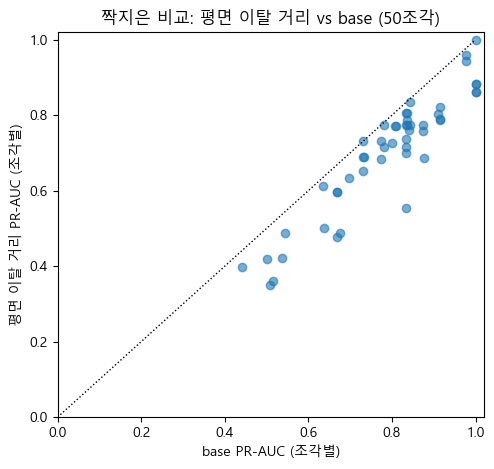

In [3]:
dist_val = pd.read_pickle('../data/val_fe.pkl')['off_plane_dist'].values

summary, folds = cv_compare('평면 이탈 거리 (점검용)', lambda fit_idx, hold_idx: dist_val[hold_idx])
cv_results.append(summary)
display(pd.DataFrame(cv_results))
plot_paired(folds, '평면 이탈 거리')

## 5-1. 지도학습 기본형: val 라벨만으로 학습

입력은 원본 V1~V30. 교차검증의 학습 조각(val의 80%, 사기 24건 + 정상 약 22,700건)으로 학습하고 채점 조각을 점수 매깁니다.

**로지스틱 회귀**
- V1~V30에 가중치를 곱해 더한 값 하나로 사기 확률을 계산합니다 (경계가 직선 하나인 가장 단순한 분류기)
- 가중치가 너무 커지지 않게 누르는 규제(L2, 기본 C=1.0)가 있는데, 변수마다 크기가 다르면 규제가 불공평하게 걸리므로 **표준화를 먼저** 합니다
  (EE와 달리 로지스틱 회귀는 스케일에 영향을 받는 모델)

**LightGBM**
- 결정 트리를 하나씩 이어 붙이며, 앞 트리들이 틀린 부분을 다음 트리가 보완하는 모델 (그래디언트 부스팅)
- 사기 24건을 외우기 쉬우므로 **얕고 조심스럽게** 설정합니다
  - `max_depth=3`, `num_leaves=7`: 트리 하나가 질문을 3번까지만
  - `min_child_samples=10`: 잎 하나에 거래가 10건 이상 있어야 함 (사기 1~2건만 따로 떼어내는 것 방지)
  - `learning_rate=0.05`, `n_estimators=200`: 조금씩 200번 보완
  - `subsample=0.8`, `colsample_bytree=0.8`: 트리마다 거래 80%, 변수 80%만 무작위로 사용 (외우기 방지)

**두 모델 공통: `class_weight='balanced'`**
사기가 정상의 약 1/950이라 그냥 학습하면 "전부 정상"이 가장 손쉬운 답이 됩니다.
balanced는 사기 1건을 정상 약 950건만큼 무겁게 쳐서 균형을 맞춥니다. (5-3에서 SMOTE와 비교)

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def fit_predict_logreg(fit_idx, hold_idx, X=X_val):
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(class_weight='balanced', C=1.0, max_iter=2000))
    model.fit(X[fit_idx], y_val[fit_idx])
    return model.predict_proba(X[hold_idx])[:, 1]   # 사기 확률

t0 = time.time()
summary, folds_logreg = cv_compare('로지스틱 회귀 (V1~V30)', fit_predict_logreg)
cv_results.append(summary)
print(f'{time.time() - t0:.0f}초')
display(pd.DataFrame(cv_results))

12초


,모델,PR-AUC 모델,PR-AUC base,PR-AUC 차이 평균,차이 표준편차,모델이 이긴 조각 비율,F1 모델 (평균±표준편차),F1 base,오탐 모델/base,평면 위 사기 모델/base
0,평면 이탈 거리 (점검용),0.7020,0.7884,-0.0863,0.0573,2%,0.8215 ± 0.0273,0.8932 ± 0.0141,10.7 / 6.4,0.0 / 0.0
1,로지스틱 회귀 (V1~V30),0.5777,0.7884,-0.2106,0.2008,14%,0.8048 ± 0.0261,0.8932 ± 0.0141,11.7 / 6.4,0.1 / 0.0


In [5]:
from lightgbm import LGBMClassifier

def make_lgbm():
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, num_leaves=7,
                          min_child_samples=10, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          reg_lambda=1.0, class_weight='balanced', random_state=42, verbose=-1)

def fit_predict_lgbm(fit_idx, hold_idx, X=X_val):
    model = make_lgbm().fit(X[fit_idx], y_val[fit_idx])
    return model.predict_proba(X[hold_idx])[:, 1]

t0 = time.time()
summary, folds_lgbm = cv_compare('LightGBM (V1~V30)', fit_predict_lgbm)
cv_results.append(summary)
print(f'{time.time() - t0:.0f}초')
display(pd.DataFrame(cv_results))

c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWa

31초


c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,모델,PR-AUC 모델,PR-AUC base,PR-AUC 차이 평균,차이 표준편차,모델이 이긴 조각 비율,F1 모델 (평균±표준편차),F1 base,오탐 모델/base,평면 위 사기 모델/base
0,평면 이탈 거리 (점검용),0.7020,0.7884,-0.0863,0.0573,2%,0.8215 ± 0.0273,0.8932 ± 0.0141,10.7 / 6.4,0.0 / 0.0
1,로지스틱 회귀 (V1~V30),0.5777,0.7884,-0.2106,0.2008,14%,0.8048 ± 0.0261,0.8932 ± 0.0141,11.7 / 6.4,0.1 / 0.0
2,LightGBM (V1~V30),0.7484,0.7884,-0.0400,0.1028,38%,0.8832 ± 0.0157,0.8932 ± 0.0141,7.0 / 6.4,0.1 / 0.0


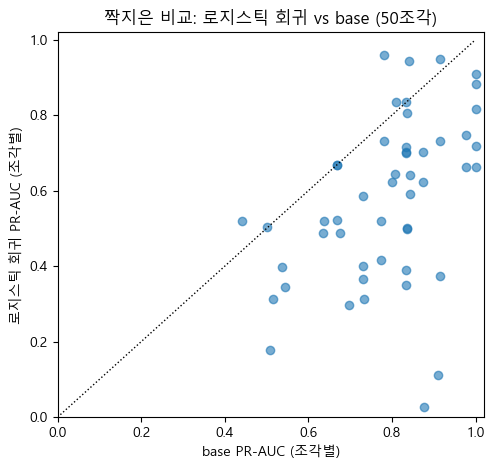

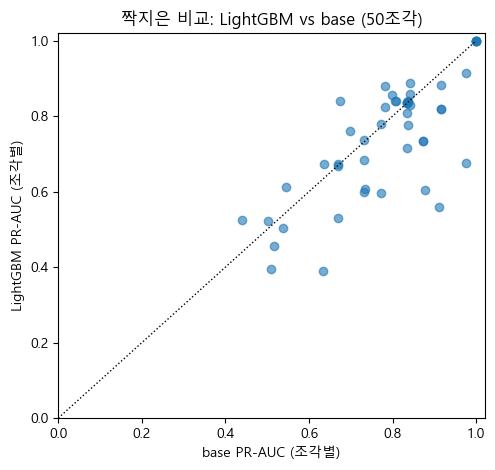

In [6]:
plot_paired(folds_logreg, '로지스틱 회귀')
plot_paired(folds_lgbm, 'LightGBM')

### 5-1 정리
| 모델 | PR-AUC 차이 (vs base) | 이긴 조각 | 오탐 (모델/base) |
|---|---|---|---|
| 로지스틱 회귀 | -0.211 | 14% | 11.7 / 6.4 |
| LightGBM | -0.040 | 38% | 7.0 / 6.4 |

- 사기 24건으로 배우는 지도학습은, train 11만 건으로 "정상의 모양"을 잡은 EE를 넘지 못했다.
- 로지스틱 회귀가 특히 약한 이유: 핵심 신호는 "평면에서 **어느 쪽으로든** 벗어났나"(제곱 거리)인데, 직선 하나로 가르는 모델은 "한쪽으로 클수록 사기"만 표현할 수 있다.
  **모델이 데이터의 구조를 표현할 수 있느냐**가 성능을 가른다.
- LightGBM은 "크거나 작으면" 같은 조건 조합이 가능해서 근접했고, 10번 중 1번은 평면 위 사기를 1건 잡았다 (비지도에서는 한 번도 없던 일, 우연일 가능성 큼).

## 5-2. 하이브리드: EE 점수를 입력 피처로 (강의자료 p.250)

각자 잘하는 것을 합칩니다.
- **EE**: train 11만 건 기반으로 "평면에서 얼마나 벗어났나"를 정확히 잰다 (직선 모델이 스스로 만들 수 없는 제곱 거리)
- **지도학습**: 라벨을 보고 "벗어난 거래 중 어떤 게 정상인지"를 배울 수 있다

입력 = V1~V30 + **log(EE 점수)**. 5-1에서 **피처 하나만** 추가한 것이라 차이는 그 피처의 효과입니다.
- EE 점수는 1 근처부터 수만까지 퍼져 있어서 log로 눌러줍니다 (로지스틱 회귀는 큰 값에 끌려가고, 트리는 log와 무관하지만 같은 입력을 쓰기 위해)
- EE 점수는 train만으로 학습한 모델에서 나왔으므로 val 라벨이 새어 들어가지 않습니다
- 모델 설정은 5-1과 동일

**이번에 볼 것**: base를 이기는지와 함께, **오탐이 줄어드는지** (EE가 이미 사기를 앞에 세워주니, 그 위에서 "평면 밖 정상"을 걸러내는 법을 배우는지)

In [7]:
# 하이브리드 입력: V1~V30 + log(EE 점수)
X_val_hyb = np.column_stack([X_val, np.log1p(base_val)])
print('하이브리드 입력 크기:', X_val_hyb.shape)

t0 = time.time()
summary, folds_logreg_hyb = cv_compare('로지스틱 회귀 (V + log EE)', lambda f, h: fit_predict_logreg(f, h, X=X_val_hyb))
cv_results.append(summary)
summary, folds_lgbm_hyb = cv_compare('LightGBM (V + log EE)', lambda f, h: fit_predict_lgbm(f, h, X=X_val_hyb))
cv_results.append(summary)
print(f'{time.time() - t0:.0f}초')
display(pd.DataFrame(cv_results))

하이브리드 입력 크기: (28462, 31)


c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWa

37초


c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,모델,PR-AUC 모델,PR-AUC base,PR-AUC 차이 평균,차이 표준편차,모델이 이긴 조각 비율,F1 모델 (평균±표준편차),F1 base,오탐 모델/base,평면 위 사기 모델/base
0,평면 이탈 거리 (점검용),0.7020,0.7884,-0.0863,0.0573,2%,0.8215 ± 0.0273,0.8932 ± 0.0141,10.7 / 6.4,0.0 / 0.0
1,로지스틱 회귀 (V1~V30),0.5777,0.7884,-0.2106,0.2008,14%,0.8048 ± 0.0261,0.8932 ± 0.0141,11.7 / 6.4,0.1 / 0.0
2,LightGBM (V1~V30),0.7484,0.7884,-0.0400,0.1028,38%,0.8832 ± 0.0157,0.8932 ± 0.0141,7.0 / 6.4,0.1 / 0.0
3,로지스틱 회귀 (V + log EE),0.6385,0.7884,-0.1498,0.1501,18%,0.8332 ± 0.0236,0.8932 ± 0.0141,10.0 / 6.4,0.1 / 0.0
4,LightGBM (V + log EE),0.7594,0.7884,-0.0290,0.0903,40%,0.8815 ± 0.0146,0.8932 ± 0.0141,7.1 / 6.4,0.1 / 0.0


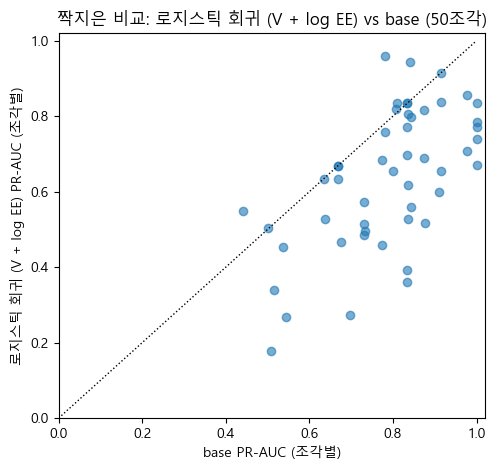

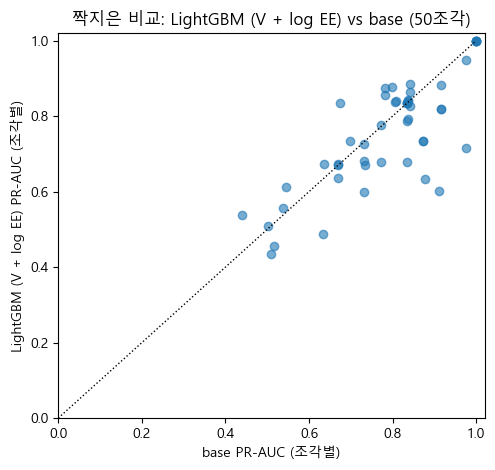

In [8]:
plot_paired(folds_logreg_hyb, '로지스틱 회귀 (V + log EE)')
plot_paired(folds_lgbm_hyb, 'LightGBM (V + log EE)')

### 5-2 정리: EE 점수를 줘도 EE보다 못하다

| 모델 | PR-AUC 차이 (vs base) | 이긴 조각 | 오탐 (모델/base) |
|---|---|---|---|
| 로지스틱 회귀 (V + log EE) | -0.150 | 18% | 10.0 / 6.4 |
| LightGBM (V + log EE) | -0.029 | 40% | 7.1 / 6.4 |

로지스틱 회귀가 log(EE)에만 가중치를 줬다면 base와 똑같은 순위가 나왔을 것이다. 더 나빠졌다는 건 **V1~V30에 준 가중치가 잡음**이라는 뜻.
학습 조각에 "사기만큼 튀는 정상"(오탐 유형)은 4건 정도뿐이라, 그걸 보고 만든 규칙은 그 몇 건에만 맞는다 (과적합).
라벨에서 얻는 정보 < 학습 과정에서 생기는 잡음.

## 5-2b. 후보 영역에 집중: "사기 vs 튀는 정상"만 배우기

전체 val 2만 8천 건 중 99%는 EE가 이미 쉽게 정상으로 판정합니다. 이 거래들은 학습에 잡음만 더하므로, 문제를 좁힙니다.

1. **후보 영역** = EE 점수가 train 상위 1% 지점보다 큰 거래 (기준을 train으로 정하므로 val 라벨 사용 없음)
2. 지도학습 모델은 **후보 영역 안에서만** 학습하고 채점 → "평면 밖으로 튄 거래 중 사기 vs 정상"이라는 좁은 문제
3. 최종 점수: 후보는 `1 + 모델 확률`(항상 비후보보다 앞), 비후보는 EE 점수 순서 그대로 (0~1 사이로 눌러서)

즉 **EE로 후보를 고르고, 지도학습은 후보의 순서만 다시 매기는** 2단계 구조입니다. 오탐 5건을 직접 겨냥합니다.
모델과 입력(V1~V30 + log EE)은 5-2와 같습니다.

In [9]:
cand_threshold = np.quantile(base_train, 1 - 0.01)   # train 상위 1% 지점
is_cand = base_val >= cand_threshold
print(f'후보 영역: val {is_cand.sum()}건 (사기 {y_val[is_cand].sum()}건 = 평면 밖 {(y_val & ~on_plane_val)[is_cand].sum()} / 평면 위 {(y_val & on_plane_val)[is_cand].sum()}, '
      f'정상 {(y_val[is_cand] == 0).sum()}건)')

base_squash = base_val / (base_val.max() + 1)   # 비후보용: EE 순서는 유지, 값은 0~1 사이

def make_focused(fit_predict_fn):
    # 후보 영역 안에서만 학습·채점하고, 비후보는 EE 순서를 그대로 쓰는 점수 함수
    def fp(fit_idx, hold_idx):
        fit_c, hold_c = fit_idx[is_cand[fit_idx]], hold_idx[is_cand[hold_idx]]
        scores = base_squash[hold_idx].copy()
        if len(hold_c) > 0:
            prob = fit_predict_fn(fit_c, hold_c)                # 후보끼리만 학습한 모델의 사기 확률
            scores[is_cand[hold_idx]] = 1 + prob                 # 후보는 항상 비후보보다 앞
        return scores
    return fp

t0 = time.time()
summary, folds_logreg_focus = cv_compare('로지스틱 회귀 (후보 집중)', make_focused(lambda f, h: fit_predict_logreg(f, h, X=X_val_hyb)))
cv_results.append(summary)
summary, folds_lgbm_focus = cv_compare('LightGBM (후보 집중)', make_focused(lambda f, h: fit_predict_lgbm(f, h, X=X_val_hyb)))
cv_results.append(summary)
print(f'{time.time() - t0:.0f}초')
display(pd.DataFrame(cv_results))

후보 영역: val 285건 (사기 25건 = 평면 밖 25 / 평면 위 0, 정상 260건)


c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWa

67초


,모델,PR-AUC 모델,PR-AUC base,PR-AUC 차이 평균,차이 표준편차,모델이 이긴 조각 비율,F1 모델 (평균±표준편차),F1 base,오탐 모델/base,평면 위 사기 모델/base
0,평면 이탈 거리 (점검용),0.7020,0.7884,-0.0863,0.0573,2%,0.8215 ± 0.0273,0.8932 ± 0.0141,10.7 / 6.4,0.0 / 0.0
1,로지스틱 회귀 (V1~V30),0.5777,0.7884,-0.2106,0.2008,14%,0.8048 ± 0.0261,0.8932 ± 0.0141,11.7 / 6.4,0.1 / 0.0
2,LightGBM (V1~V30),0.7484,0.7884,-0.0400,0.1028,38%,0.8832 ± 0.0157,0.8932 ± 0.0141,7.0 / 6.4,0.1 / 0.0
3,로지스틱 회귀 (V + log EE),0.6385,0.7884,-0.1498,0.1501,18%,0.8332 ± 0.0236,0.8932 ± 0.0141,10.0 / 6.4,0.1 / 0.0
4,LightGBM (V + log EE),0.7594,0.7884,-0.0290,0.0903,40%,0.8815 ± 0.0146,0.8932 ± 0.0141,7.1 / 6.4,0.1 / 0.0
5,로지스틱 회귀 (후보 집중),0.7797,0.7884,-0.0086,0.0561,22%,0.8916 ± 0.0118,0.8932 ± 0.0141,6.5 / 6.4,0.0 / 0.0
6,LightGBM (후보 집중),0.8087,0.7884,0.0204,0.0615,42%,0.8966 ± 0.0132,0.8932 ± 0.0141,6.2 / 6.4,0.0 / 0.0


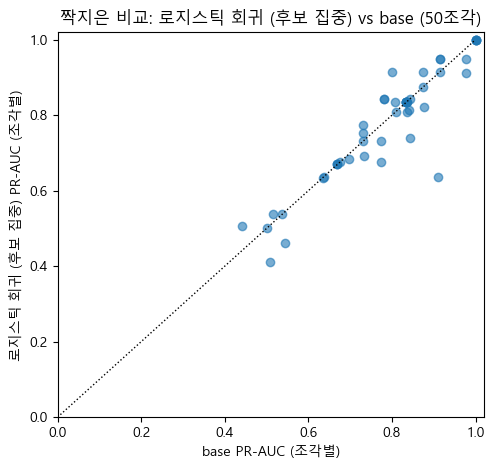

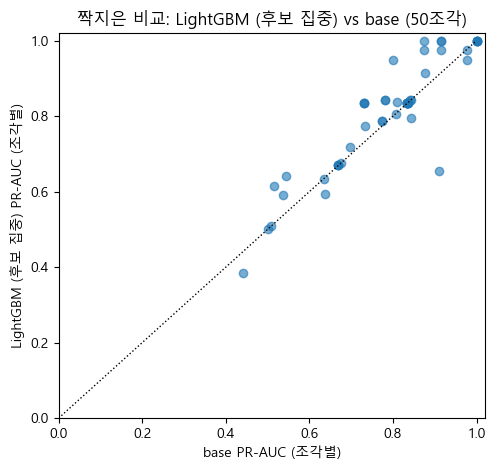

In [10]:
plot_paired(folds_logreg_focus, '로지스틱 회귀 (후보 집중)')
plot_paired(folds_lgbm_focus, 'LightGBM (후보 집중)')

### 5-2b 정리: 방향은 맞지만 흔들림 안의 차이

| 모델 | PR-AUC 차이 (vs base) | 이긴 조각 | F1 (모델/base) | 오탐 (모델/base) |
|---|---|---|---|---|
| LightGBM (V + log EE), 전체 학습 | -0.029 ± 0.090 | 40% | 0.882 / 0.893 | 7.1 / 6.4 |
| 로지스틱 회귀 (후보 집중) | -0.009 ± 0.056 | 22% | 0.892 / 0.893 | 6.5 / 6.4 |
| **LightGBM (후보 집중)** | **+0.020** ± 0.062 | 42% | 0.897 / 0.893 | 6.2 / 6.4 |

- 후보 영역: val 285건 (평면 밖 사기 25건 전부 + 정상 260건). 평면 위 사기는 0건 → 이 구조로는 원리상 못 잡음
- 같은 LightGBM이 학습 범위만 좁혀서 -0.029 → +0.020. 쉬운 정상 99%를 빼 **문제를 좁히니** 잡음 대신 핵심 구분에 집중 → 데이터가 적을 때의 정공법
- 하지만 +0.020은 표준편차(0.062)의 1/3, 이긴 조각 42%로 미리 정한 기준(70%)에 미달. F1 차이(+0.003)도 base 자체의 흔들림(±0.014)보다 작음
- **미리 정한 기준을 결과를 본 뒤에 바꾸지 않는다** (그게 val에 맞추는 과적합) → 제출하지 않음

## Phase 5 요약

| 시도 | PR-AUC 차이 (vs base) | 결과 |
|---|---|---|
| 평면 이탈 거리 (틀 점검용) | -0.086 | 리더보드 순서 재현 → 평가 틀 정상 |
| 로지스틱 회귀 (V1~V30) | -0.211 | 직선 모델은 "어느 쪽으로든 벗어남"(제곱 거리)을 표현 못 함 |
| LightGBM (V1~V30) | -0.040 | 근접, 10번 중 1번 평면 위 사기 1건 |
| 로지스틱 회귀 / LightGBM (+ log EE) | -0.150 / -0.029 | V1~V30 가중치가 잡음 → EE 점수만 쓸 때보다 못함 |
| 로지스틱 회귀 / LightGBM (후보 집중) | -0.009 / **+0.020** | 방향은 맞지만 흔들림 안 |

**결론**
1. **라벨 30건으로는 오탐을 걸러낼 규칙을 확실히 배울 수 없다.** 학습 조각의 "사기만큼 튀는 정상"은 4건 정도뿐이라, 거기서 만든 규칙은 그 몇 건에만 맞는다.
2. **평면 위 사기는 지도학습으로도 못 잡았다.** 비지도(03c, 04, 04c)에 이어 라벨로도 신호가 없음을 확인.
3. **base(EE 1차 공분산 + 0.12%, Public 0.9305 / Private 0.9054)가 이 데이터로 확인 가능한 최선**으로 최종 확정.

**이 Phase에서 배운 것**
- 양성이 적을 때는 **반복 교차검증 + 같은 조각에서 짝지은 비교**로 흔들림의 크기부터 잰다. 판단 기준(이긴 조각 70%)은 실험 전에 정한다.
- 평가 틀은 **답을 아는 비교**(리더보드로 확인된 순서)로 먼저 점검한다.
- 지도학습은 라벨이 적으면 비지도보다 못할 수 있다. 정상 11만 건의 "모양"이 사기 24건의 "예시"보다 많은 정보를 준다.
- 모델이 데이터 구조를 **표현할 수 있는지** 확인한다 (직선 모델 vs 제곱 거리).
- 데이터가 적으면 **문제를 좁혀라** (후보 영역 집중: -0.029 → +0.020).
- 하이브리드에서 원래 점수보다 못하면, 추가한 피처가 정보가 아니라 잡음이라는 신호.
